In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
iso_data_dir = "../../../data/"
signal_type = "dynamic"  # dynamic or traditional
file_name = "012025_" + signal_type + ".csv"
file_path = iso_data_dir + file_name
date = "1/17/2025"

df = pd.read_csv(file_path)

print(df.head())

  Unnamed: 0  1/1/2025  1/2/2025  1/3/2025  1/4/2025  1/5/2025  1/6/2025  \
0    0:00:00 -0.999300  0.672976 -0.974665  0.038908 -0.059377 -0.028358   
1    0:00:02 -0.999241  0.652066 -0.965220  0.031900 -0.029303  0.036790   
2    0:00:04 -0.999973  0.635609 -0.947643  0.026199  0.001650  0.072859   
3    0:00:06 -0.999976  0.623370 -0.999633  0.013269  0.038735  0.148291   
4    0:00:08 -0.999980  0.613617 -0.999117 -0.003862  0.078129  0.222244   

   1/7/2025  1/8/2025  1/9/2025  ...  1/22/2025  1/23/2025  1/24/2025  \
0  0.649107 -0.609764  1.000063  ...   0.531411  -0.126601  -0.195508   
1  0.661217 -0.607512  0.999998  ...   0.502289  -0.137669  -0.192615   
2  0.665801 -0.598475  0.999995  ...   0.484451  -0.139485  -0.188004   
3  0.670476 -0.594001  0.999991  ...   0.441762  -0.158652  -0.179855   
4  0.672644 -0.588965  0.999988  ...   0.411880  -0.177566  -0.170049   

   1/25/2025  1/26/2025  1/27/2025  1/28/2025  1/29/2025  1/30/2025  1/31/2025  
0   0.123271  -0.767179

In [3]:
p_bar = 0 # MW
r = 1   # MW

ptarget = p_bar + df[date] * r

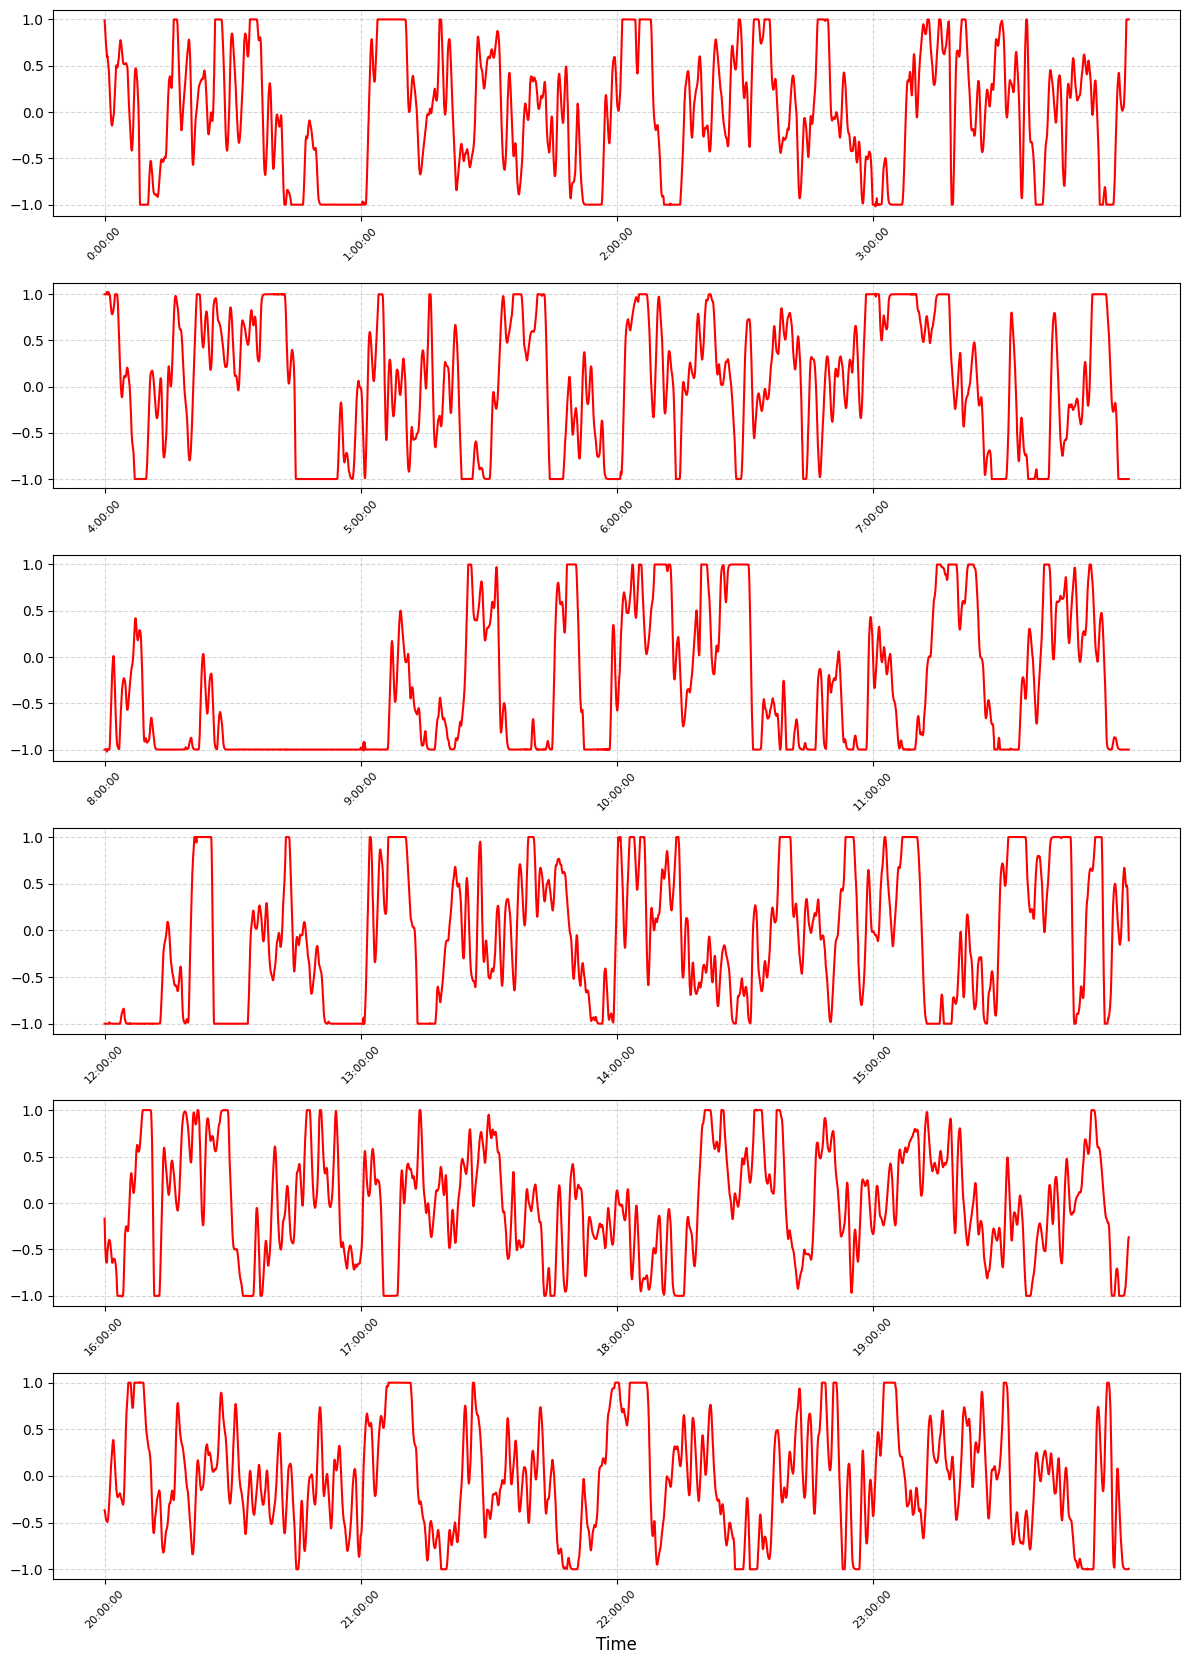

In [4]:
# Extract time labels (assuming the 0th column contains time)
time_labels = df.iloc[:, 0]  # Extract the 0th column for x-axis labels

# Ensure all time_labels are strings
time_labels = [str(label) for label in time_labels]

# Compute ptarget
ptarget = p_bar + df[date] * r

# Number of data points per hour
data_points_per_hour = 1800

# Number of data points per 4-hour interval
data_points_per_4_hours = data_points_per_hour * 4

# Create subplots
fig, axes = plt.subplots(6, 1, figsize=(12, 18))  # 6 rows, 1 column of subplots

# Create the 6 subplots for 4-hour intervals
for i in range(6):
    # Extract data for the current 4-hour interval
    start_idx = i * data_points_per_4_hours
    end_idx = start_idx + data_points_per_4_hours
    interval_time_labels = time_labels[start_idx:end_idx]
    interval_ptarget = ptarget[start_idx:end_idx]

    # Calculate ticks for each hour within the interval
    tick_positions = range(0, len(interval_time_labels), data_points_per_hour)
    tick_labels = [interval_time_labels[j] for j in tick_positions]

    # Plot data in the current subplot
    axes[i].plot(interval_time_labels, interval_ptarget, label=f'Interval {i + 1}', color='red', linestyle='-', markevery=data_points_per_hour)
    axes[i].set_xticks(tick_positions)  # Set x-axis ticks
    axes[i].set_xticklabels(tick_labels, rotation=45, fontsize=8)  # Set tick labels
    # axes[i].set_ylabel('P Target (MW)', fontsize=10)  # Label for y-axis
    axes[i].grid(visible=True, linestyle='--', alpha=0.5)  # Add grid
    # axes[i].legend(fontsize=10)  # Add legend

# Add a shared title and x-label
# fig.suptitle('P Target Over 24 Hours (Split into 4-Hour Intervals)', fontsize=14)
plt.xlabel('Time', fontsize=12)

# Optimize layout and display the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()


Selected 10 block(s), each 1 hour(s) long, ranked by mean closest to zero:



,start_hour,end_hour,mean,abs_mean,near_zero
Selected block,,,,,
1,1,2,0.019945,0.019945,True
2,3,4,0.015522,0.015522,True
3,4,5,0.031531,0.031531,False
4,13,14,-0.015305,0.015305,True
5,18,19,-0.005240,0.005240,True
6,19,20,-0.002293,0.002293,True
7,20,21,-0.041494,0.041494,False
8,21,22,-0.027803,0.027803,False
9,22,23,-0.015491,0.015491,True



6 selected block(s) have |mean| <= 0.02.


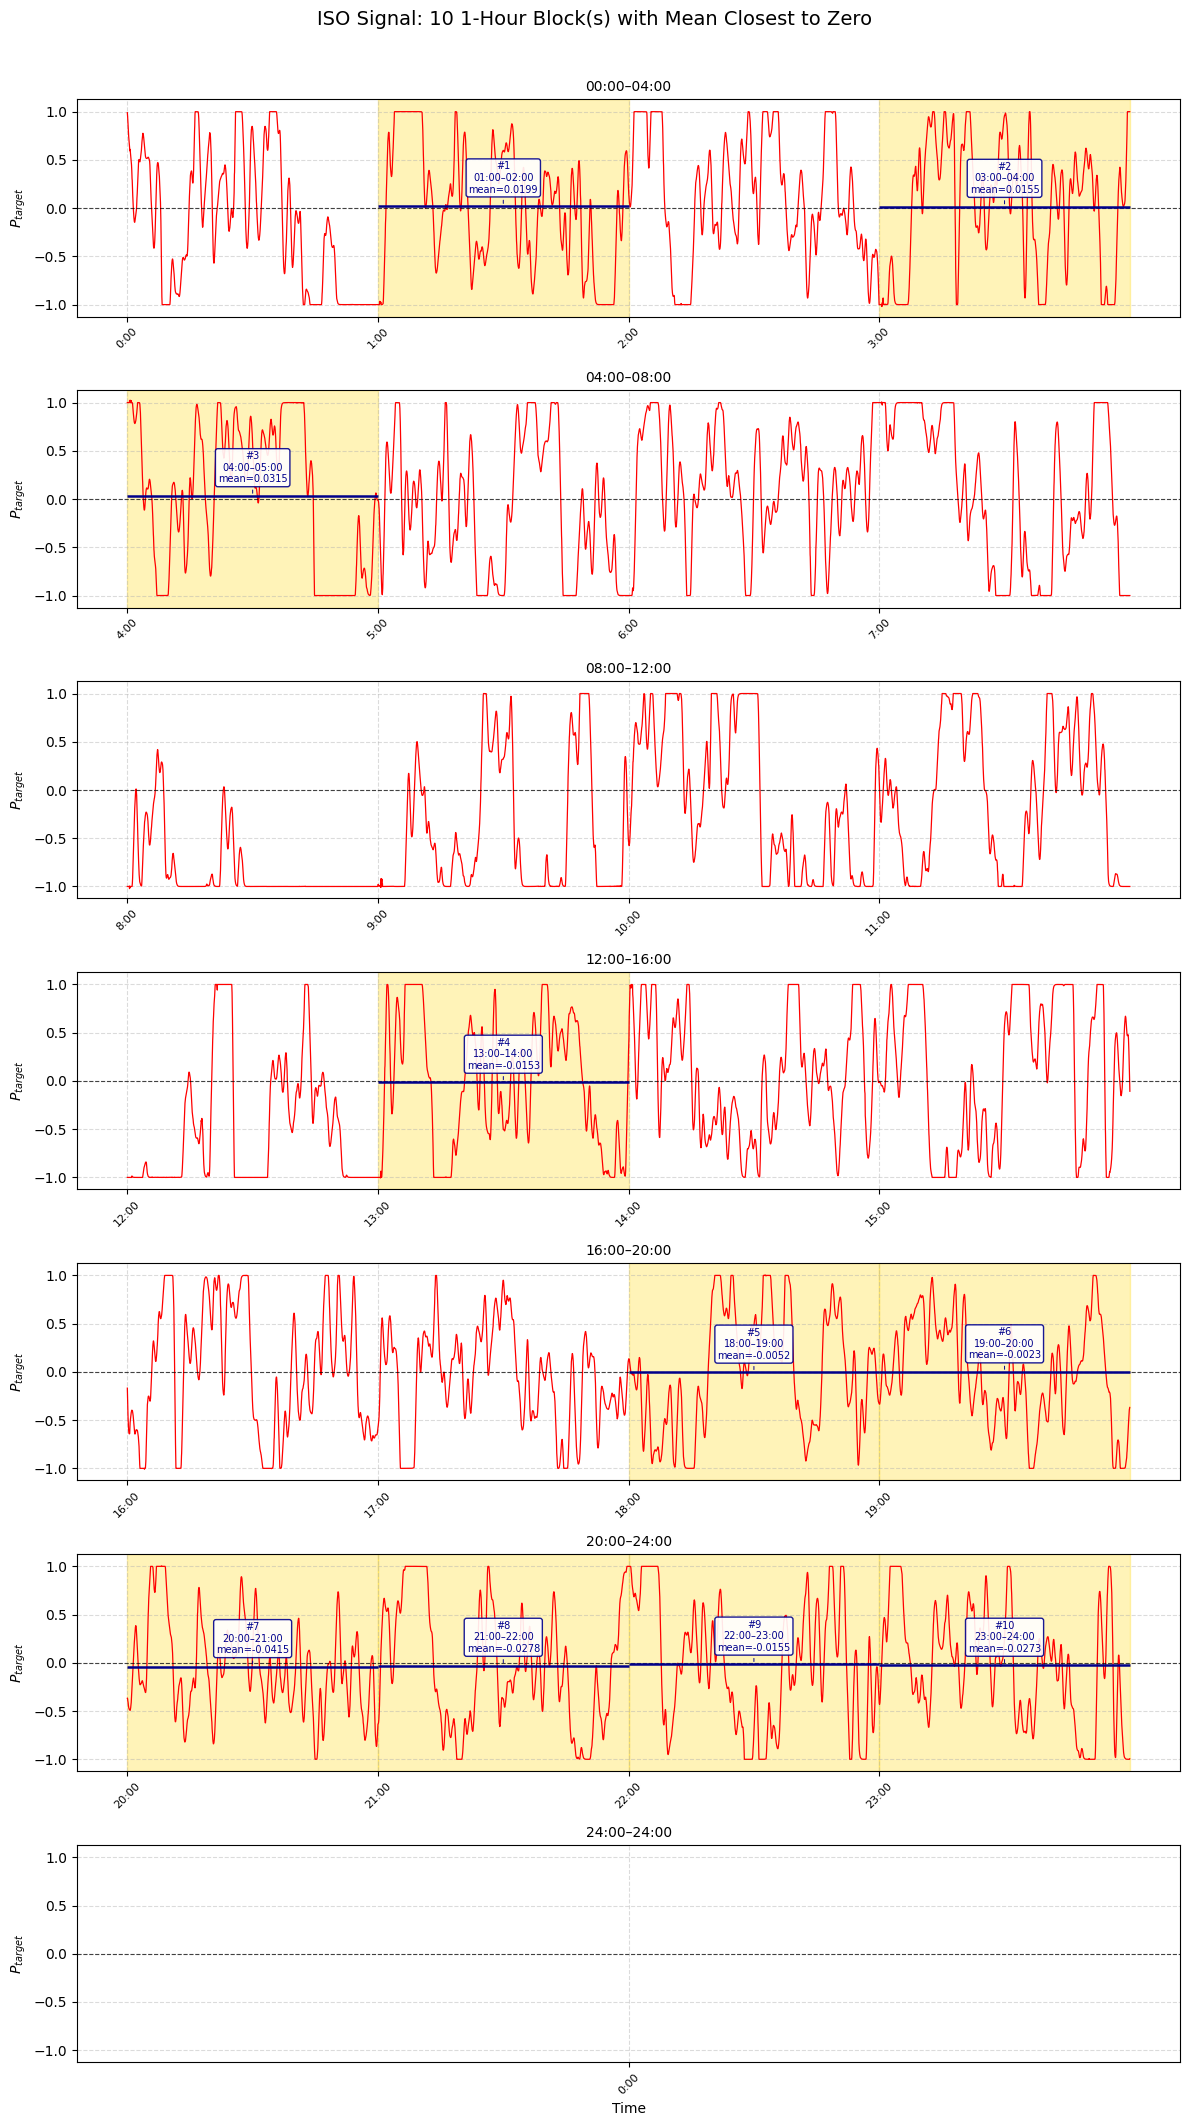

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# SETTINGS
# ============================================================
data_points_per_hour = 1800
block_hours = 1          # Change to 2, 3, etc. if each block should span multiple hours
max_blocks_to_label = 10 # Find up to this many non-overlapping blocks
near_zero_tolerance = 0.02  # Only used to report which chosen blocks are "near zero"

# Recompute these so this cell can run independently after Cells 1-3.
time_labels = [str(label) for label in df.iloc[:, 0]]
ptarget = (p_bar + df[date] * r).reset_index(drop=True)

# ============================================================
# 1. SCORE EVERY WHOLE-HOUR BLOCK BY HOW CLOSE ITS MEAN IS TO 0
# ============================================================
block_size = block_hours * data_points_per_hour
n_complete_blocks = len(ptarget) // block_size

candidates = []

for block_id in range(n_complete_blocks):
    start_idx = block_id * block_size
    end_idx = start_idx + block_size

    block_signal = ptarget.iloc[start_idx:end_idx]
    block_mean = block_signal.mean()

    candidates.append({
        "block_id": block_id,
        "start_idx": start_idx,
        "end_idx": end_idx,
        "start_hour": block_id * block_hours,
        "end_hour": (block_id + 1) * block_hours,
        "mean": block_mean,
        "abs_mean": abs(block_mean),
    })

# Smallest absolute mean = closest to zero.
candidates = sorted(candidates, key=lambda x: x["abs_mean"])

# With fixed whole-hour blocks these cannot overlap, but this preserves
# correct behavior if block_hours is changed later.
selected_blocks = []

for candidate in candidates:
    overlaps_existing = any(
        candidate["start_idx"] < selected["end_idx"]
        and candidate["end_idx"] > selected["start_idx"]
        for selected in selected_blocks
    )

    if not overlaps_existing:
        selected_blocks.append(candidate)

    if len(selected_blocks) == max_blocks_to_label:
        break

# Sort chronologically for the table and plot labels.
selected_blocks = sorted(selected_blocks, key=lambda x: x["start_idx"])

# ============================================================
# 2. PRINT THE RESULTS
# ============================================================
results = pd.DataFrame(selected_blocks)[
    ["start_hour", "end_hour", "mean", "abs_mean"]
].copy()

results["near_zero"] = results["abs_mean"] <= near_zero_tolerance
results.index = np.arange(1, len(results) + 1)
results.index.name = "Selected block"

print(
    f"Selected {len(results)} block(s), each {block_hours} hour(s) long, "
    f"ranked by mean closest to zero:\n"
)
display(results.style.format({
    "mean": "{:.6f}",
    "abs_mean": "{:.6f}",
}))

if results["near_zero"].any():
    print(
        f"\n{results['near_zero'].sum()} selected block(s) have "
        f"|mean| <= {near_zero_tolerance}."
    )
else:
    print(
        f"\nNone of the selected blocks met |mean| <= {near_zero_tolerance}; "
        "the plot still shows the closest available blocks."
    )

# ============================================================
# 3. RECREATE CELL 4, BUT HIGHLIGHT / LABEL THE SELECTED HOURS
# ============================================================
data_points_per_4_hours = data_points_per_hour * 4
n_panels = int(np.ceil(len(ptarget) / data_points_per_4_hours))

fig, axes = plt.subplots(
    n_panels,
    1,
    figsize=(12, 3 * n_panels),
    sharey=True
)

if n_panels == 1:
    axes = [axes]

for panel_idx, ax in enumerate(axes):
    panel_start_idx = panel_idx * data_points_per_4_hours
    panel_end_idx = min(panel_start_idx + data_points_per_4_hours, len(ptarget))

    panel_signal = ptarget.iloc[panel_start_idx:panel_end_idx]
    panel_labels = time_labels[panel_start_idx:panel_end_idx]
    panel_x = np.arange(len(panel_signal))

    # Base signal, matching Cell 4's overall plotting approach.
    ax.plot(
        panel_x,
        panel_signal,
        color="red",
        linestyle="-",
        linewidth=0.9,
        label="ISO signal"
    )
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

    # Hourly x-axis labels.
    tick_positions = np.arange(
        0,
        len(panel_signal),
        data_points_per_hour
    )
    tick_labels = [
        ":".join(panel_labels[pos].split(":")[:2])
        for pos in tick_positions
    ]

    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=45, fontsize=8)
    ax.grid(visible=True, linestyle="--", alpha=0.45)

    # Shade and annotate every selected block that lies in this panel.
    for selected_num, block in enumerate(selected_blocks, start=1):
        overlap_start = max(block["start_idx"], panel_start_idx)
        overlap_end = min(block["end_idx"], panel_end_idx)

        if overlap_start >= overlap_end:
            continue

        local_start = overlap_start - panel_start_idx
        local_end = overlap_end - panel_start_idx

        # Highlight selected interval.
        ax.axvspan(local_start, local_end, color="gold", alpha=0.28)

        # Draw its mean across the highlighted block.
        ax.hlines(
            y=block["mean"],
            xmin=local_start,
            xmax=local_end,
            color="darkblue",
            linewidth=1.8
        )

        # Label near the midpoint of the selected block.
        midpoint = (local_start + local_end) / 2
        y_top = panel_signal.max()
        y_bottom = panel_signal.min()
        y_offset = 0.06 * (y_top - y_bottom) if y_top != y_bottom else 0.01

        ax.annotate(
            (
                f"#{selected_num}\n"
                f"{block['start_hour']:02d}:00–{block['end_hour']:02d}:00\n"
                f"mean={block['mean']:.4f}"
            ),
            xy=(midpoint, block["mean"]),
            xytext=(midpoint, block["mean"] + y_offset),
            ha="center",
            va="bottom",
            fontsize=7,
            color="darkblue",
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor="darkblue",
                alpha=0.9
            ),
            arrowprops=dict(
                arrowstyle="-",
                color="darkblue",
                linewidth=0.7
            )
        )

    panel_start_hour = panel_start_idx // data_points_per_hour
    panel_end_hour = min(
        panel_end_idx // data_points_per_hour,
        24
    )

    ax.set_title(
        f"{panel_start_hour:02d}:00–{panel_end_hour:02d}:00",
        fontsize=10
    )
    ax.set_ylabel(r"$P_{target}$")

axes[-1].set_xlabel("Time")

fig.suptitle(
    f"ISO Signal: {len(selected_blocks)} {block_hours}-Hour Block(s) "
    "with Mean Closest to Zero",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()